# UTSA CS 3793/5233: Lab-3

**Baggs - Ben - (ojj408)**


## Learning Objectives

Implement 2 different machine learning algorithms
*   Stochastic Gradient Descent
*   ID3 Decision Tree



## Description

This assignment is focused on **machine learning**, mainly on the implementation of 2 different algorithms - Stochastic Gradient Descent & ID3 decision tree. 
The assignment is divided into two sections, each for one unique ML algorithm. 

The base structure and comments are provided on what should be done. You can use some libraries that help support you for the successful completion of the assignment. However, you **CANNOT** use a complete library that contains the implementation of ML algorithms. You can get pieces of code from online, but please cite the source properly.

SOURCES:

https://realpython.com/gradient-descent-algorithm-python/#gradient-of-a-function-calculus-refresher
https://machinelearningmastery.com/implement-perceptron-algorithm-scratch-python/
https://sefiks.com/2017/11/20/a-step-by-step-id3-decision-tree-example/
https://github.com/random-forests/tutorials/blob/master/decision_tree.py
https://gist.github.com/jaradc/eeddf20932c0347928d0da5a09298147
https://guillermoarriadevoe.com/blog/building-a-id3-decision-tree-classifier-with-python

##Import Libraries

Write all the import statements here. This should be for both algorithm implmentations. As mentioned before, you can not use any premade ML libraries.

In [1]:
# import all required libraries
from csv import reader
import matplotlib.pyplot as plt
import numpy as np
import random

In [2]:
#IMPORTED CLASSES FROM SOURCES LINE ON 12 AND 13
class Leaf:
    def __init__(self, rows, question):
        self.predictions = class_counts(rows)
        self.question = question
class Decision_Node:
    def __init__(self,
                 question,
                 true_branch,
                 false_branch):
        self.question = question
        self.true_branch = true_branch
        self.false_branch = false_branch
class Question:
    def __init__(self, column, value):
        self.column = column
        self.value = value
    def match(self, example):
        val = example[self.column]
        if is_numeric(val):
            return val >= self.value
        else:
            return val == self.value
    def __repr__(self):
        condition = "="
        if is_numeric(self.value):
            condition = ">="
        return "%s %s %s:" % (
            header[self.column], condition, str(self.value))

In [3]:
#IMPORTED METHODS LINES 12 AND 13
def entropy(labels, base=2):
  value,counts = np.unique(labels, return_counts=True)
  return entropy(counts, base=2)
def is_numeric(value):
    return isinstance(value, int) or isinstance(value, float)
def class_counts(rows):
    counts = {} 
    for row in rows:
        label = row[-1]
        if label not in counts:
            counts[label] = 0
        counts[label] += 1
    return counts
def score(rows):
    counts = class_counts(rows)
    entropy = 1
    for lbl in counts:
        prob_of_lbl = counts[lbl] / float(len(rows))
        entropy -= prob_of_lbl**2
    return entropy
def info_gain(left, right, current_uncertainty):
    p = float(len(left)) / (len(left) + len(right))
    return current_uncertainty - p * score(left) - (1 - p) * score(right)
def partition(rows, question):
    true_rows, false_rows = [], []
    for row in rows:
        if question.match(row):
            true_rows.append(row)
        else:
            false_rows.append(row)
    return true_rows, false_rows
def find_best_split(rows):
    best_gain = 0  
    best_question = None  
    current_uncertainty = score(rows)
    n_features = len(rows[0]) - 1  
    for col in range(n_features): 
        values = set([row[col] for row in rows])
        for val in values:  
            question = Question(col, val)
            true_rows, false_rows = partition(rows, question)
            if len(true_rows) == 0 or len(false_rows) == 0:
                continue
            gain = info_gain(true_rows, false_rows, current_uncertainty)
            if gain >= best_gain:
                best_gain, best_question = gain, question
    return best_gain, best_question
def build_tree(rows):
    gain, question = find_best_split(rows)
    if gain == 0:
        return Leaf(rows, question)
    true_rows, false_rows = partition(rows, question)
    true_branch = build_tree(true_rows)
    false_branch = build_tree(false_rows)
    return Decision_Node(question, true_branch, false_branch)
def print_tree(node, spacing=""):
    if isinstance(node, Leaf):
        print (spacing + "Class=", print_leaf(node.predictions), end = ' ')
        return
    print (spacing + str(node.question), end = ' ')
    print (' ')
    print_tree(node.true_branch, spacing + " ")
    print (' ')
    print_tree(node.false_branch, spacing + " ")
def classify(row, node):
    if isinstance(node, Leaf):
        return node.predictions
    if node.question.match(row):
        return classify(row, node.true_branch)
    else:
        return classify(row, node.false_branch)
def print_leaf(counts):
    total = sum(counts.values()) * 1.0
    probs = {}
    for lbl in counts.keys():
        probs[lbl] = str(int(counts[lbl] / total * 100)) + "%"
    return probs
def print_accuracy(rows):
    count = 0
    length = len(rows)
    for row in rows:
        result = classify(row, my_tree)
        left = result.get('0')
        if left is None:
            left=0
        right = result.get('1')
        if right is None:
            right=0
        if left>right:
            result=0
        else:
            result=1
        if result != int(row[-1]):
            count=count+1
    return((length-count)/length * 100)

#Stochastic Gradient Descent

In this section, you will implement the Stochastic Gradient Descent algorithm. The training is for a **binary classification** task i.e. each instance will have a class value of 0 or 1. Also, assume that you are given **all binary-valued attributes** and that there are **no missing values** in the train or test data. 


##Algorithm

(20 points)

Following are the data files that will be provided to you for the gradient descent algorithm implementation.

*   Training file - 'gd-train.dat'
*   Testing file - 'gd-test.dat'

*Both these files should be present in the same folder as this code file.* In these files, only non-space characters are relevant. The first line contains the attribute names. All the other lines are different example instances to be used for the algorithm. Each column holds values of the attributes, whereas the last column holds the class label for that instance.

Write the code in the following code block, structure is provided. Instructions on the steps to follow are provided as comments.



In [4]:
# Data file name variables
train = 'gd-train.dat'
test = 'gd-test.dat'
xtrain = list()
ytrain = list()
xtest = list()
ytest = list()
# Threshold of 0.5 will be used to classify the instance for the test. 
#If the value is >= 0.5, classify as 1 or else 0.
threshold = 0.5
# Open the training file
training = list()
testing = list()
with open(train, 'r') as file:
        csv_reader = reader(file, delimiter='\t')
        for row in csv_reader:
            if not row:
                continue
            training.append(row)
with open(test, 'r') as file2:
        csv_reader = reader(file2, delimiter='\t')
        for row in csv_reader:
            if not row:
                continue
            testing.append(row)
# Read the first line to get the number of attributes
number_of_attributes = len(training[0][0:-1])
# Initialize weights for all attributes to 0
weights = [0 for i in range(number_of_attributes+1)]
# Read all the training instances
training = training[1:]
testing = testing[1:]
#print(training)
# The learning rate for the algorithm. You will loop through the data and train for different learning rates from 0.05-1, in increments of 0.05.  
learning_rate = 0.05 
# Main algorithm loop
# Loop through all the different learning rates as mentioned above
# For each learning rate selected, train the and calculate the weights
# Loop through all the data instances in the training file. 
#We will only perform 1 iteration of the complete training data
# For each instance, get the output class label using the original weights

def predict(row, weights):
    activation = weights[0]
    for i in range(len(row)-1):
        activation += weights[i + 1] * int(row[i])
    if activation >= threshold:
        prediction = 1
    else:
        prediction = 0
    return prediction

while learning_rate <=1:
    for row in training:
        prediction = predict(row, weights)
            # Get the error value using the provided class label
        error = int(row[-1]) - prediction  
            # Update the weights using the selected learning rate
        weights[0] = weights[0] + learning_rate * error
        for i in range(len(row)-1):
            weights[i+1] = weights[i + 1] + learning_rate * error * int(row[i])
    #print(weights)
    # Use the above trained model to predict the training data and print the accuracy as "Accuracy for LR of 0.05 on Training set = x %"
    count=0
    for row in training:
        prediction = predict(row,weights)
        if int(row[-1]) == prediction:
            count+=1
    accuracy=count/len(training)*100
    print("Accuracy for LR of %f on Training set = training %f percent" % (learning_rate,accuracy))
    xtrain.append(learning_rate)
    ytrain.append(accuracy)
    # For each training instance, predict the output label using the threshold of 0.5
    # Compare it with the ground truth class label and calculate the positive and negative classification for accuracy
    # Use the above trained model to predict the testing data and print the accuracy as "Accuracy for LR of 0.1 on Testing set = x %"
    count2=0
    for row in testing:
        prediction = predict(row,weights)
        if int(row[-1]) == prediction:
            count2+=1
    accuracy=count2/len(testing)*100
    print("Accuracy for LR of %f on Testing set = training %f percent" % (learning_rate,accuracy))
    xtest.append(learning_rate)
    ytest.append(accuracy)
    # For each testing instance, predict the output label using the threshold of 0.5
    # Compare it with the ground truth class label and calculate the positive and negative classification for accuracy
    learning_rate+=0.05

#I really think we should have done more than 1 iteration of training
#looks like learning rate of 0.2-0.4 is the best for both


Accuracy for LR of 0.050000 on Training set = training 72.000000 percent
Accuracy for LR of 0.050000 on Testing set = training 70.500000 percent
Accuracy for LR of 0.100000 on Training set = training 70.000000 percent
Accuracy for LR of 0.100000 on Testing set = training 70.000000 percent
Accuracy for LR of 0.150000 on Training set = training 73.000000 percent
Accuracy for LR of 0.150000 on Testing set = training 64.750000 percent
Accuracy for LR of 0.200000 on Training set = training 69.000000 percent
Accuracy for LR of 0.200000 on Testing set = training 71.250000 percent
Accuracy for LR of 0.250000 on Training set = training 69.000000 percent
Accuracy for LR of 0.250000 on Testing set = training 71.000000 percent
Accuracy for LR of 0.300000 on Training set = training 73.000000 percent
Accuracy for LR of 0.300000 on Testing set = training 63.000000 percent
Accuracy for LR of 0.350000 on Training set = training 71.000000 percent
Accuracy for LR of 0.350000 on Testing set = training 64.

##Extra Credit - Accuracy Plots

(2 points)

Use the above accuracy results on the training and testing data and write code to plot the graphs as mentioned in the code block below.



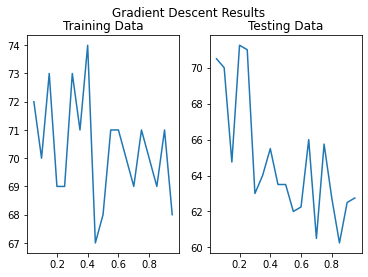

In [5]:
# Plot the graphs for accuracy results.
# There will be 2 graphs - one for training data and the other for testing data
# For each graph,
    # X-axis will be the learning rate going from 0.05-1 in increments on 0.05
    # Y-axis will be the accuracy values at the selected learning rate.

fig, (ax1,ax2) = plt.subplots(1,2)
fig.suptitle("Gradient Descent Results")
ax1.set_title("Training Data")
ax1.plot(xtrain,ytrain)
ax2.set_title("Testing Data")
ax2.plot(xtest,ytest)

#ID3 Decision Tree

In this section, you will implement the ID3 Decision Tree algorithm. The training is for a **binary classification** task i.e. each instance will have a class value of 0 or 1. Also, assume that you are given **all binary-valued attributes** and that there are **no missing values** in the train or test data. 


## Algorithm

(30 points)

Following are the data files that will be provided to you for the ID3 algorithm implementation.

*   Training file - 'id3-train.dat'
*   Testing file - 'id3-test.dat'

*Both these files should be present in the same folder as this code file.* In these files, only non-space characters are relevant. The first line contains the attribute names. All the other lines are example instances to be used for the algorithm. Each column holds values of the attributes, whereas the last column holds the class label for that instance.

In a decision tree, if you reach a leaf node but still have examples that belong to different classes, then choose the most frequent class (among the instances at the leaf node). If you reach a leaf node in the decision tree and have no examples left or the examples are equally split among multiple classes, then choose the class that is most frequent in the entire training set. You do not need to implement pruning. Also, don’t forget to use logarithm base 2 when computing entropy and set (0 log 0) to 0.

Write the code in the following code block, structure is provided. Instructions on the steps to follow are provided as comments. The code should output the following 3 things:

*   Print the Decision Tree created, in the following example format:

    ```
    attr1 = 0 :
        attr2 = 0 :
            attr3 = 0 : 1
            attr3 = 1 : 0
        attr3 = 1 :
            attr4 = 0 : 0
            attr4 = 1 : 1
    attr1 = 1 :
        attr2 = 1 : 1

    ```

*   Accuracy on the Training data = x %
*   Accuracy on the Test data = x %





In [6]:
# Following is the base code structure. You are free to change the code structure as you see fit, 
#maybe even create more functions.


# Pseudocode for the ID3 algorithm. Use this to create a function. You can also have more functions 
#for the other parts mentioned.
# def ID3(data, root, attributesRemaining):
# If you reach a leaf node in the decision tree and have no examples left or the examples are 
#equally split among multiple classes
# Choose and the class that is most frequent in the entire training set and return the updated tree
# If all the instances have only one class label
# Make this as the leaf node and use the label as the class value of the node and return the 
#updated tree
# If you reached a leaf node but still have examples that belong to different classes 
#(there are no remaining attributes to be split)
# Assign the most frequent class among the instances at the leaf node and return the updated tree
# Find the best attribute to split by calculating the maximum information gain from the attributes 
#remaining by calculating the entropy
# Split the tree using the best attribute and recursively call the ID3 function using DFS 
#to fill the sub-tree
# return the root as the tree



# Data file name variables
train = 'id3-train.dat'
test = 'id3-test.dat'



# Read the first line in the training data file, to get the number of attributes
training = list()
testing = list()
from csv import reader
training = list()

with open(train, 'r') as file:
        csv_reader = reader(file, delimiter='\t')
        for row in csv_reader:
            if not row:
                continue
            training.append(row)
with open(test, 'r') as file2:
        csv_reader = reader(file2, delimiter='\t')
        for row in csv_reader:
            if not row:
                continue
            testing.append(row)
            
header = training[0]
training = training[1:]
testing = testing[1:]
# Read all the training instances and the ground truth class labels.
# Create the decision tree by implementing the ID3 algorithm. Pseudocode provided above.
# Print the tree in the example format mentioned.
my_tree = build_tree(training)
print_tree(my_tree)
# Use the above created tree to predict the training data and print the accuracy as 
#"Accuracy on the Training data = x %"

#NEXT CELL

# For each training instance, predict the output label
# Compare it with the ground truth class label and calculate the accuracy accordingly
# Use the above created tree to predict the testing data and print the accuracy as 
#"Accuracy on the Test data = x %"

#NEXT CELL

# For each testing instance, predict the output label
# Compare it with the ground truth class label and calculate the accuracy accordingly



attr5 = 0:  
 attr6 = 0:  
  attr2 = 0:  
   attr1 = 1:  
    attr4 = 0:  
     attr3 = 0:  
      Class= {'1': '6%', '0': '93%'}  
      Class= {'0': '100%'}  
     Class= {'0': '100%'}  
    attr4 = 1:  
     attr3 = 1:  
      Class= {'0': '92%', '1': '7%'}  
      Class= {'0': '92%', '1': '7%'}  
     attr3 = 0:  
      Class= {'0': '88%', '1': '11%'}  
      Class= {'1': '25%', '0': '75%'}  
   attr4 = 0:  
    attr3 = 0:  
     Class= {'0': '100%'}  
     attr1 = 0:  
      Class= {'0': '100%'}  
      Class= {'0': '88%', '1': '11%'}  
    attr1 = 1:  
     attr3 = 0:  
      Class= {'1': '33%', '0': '66%'}  
      Class= {'0': '76%', '1': '23%'}  
     attr3 = 0:  
      Class= {'0': '90%', '1': '10%'}  
      Class= {'0': '83%', '1': '16%'}  
  attr4 = 1:  
   attr2 = 0:  
    attr1 = 0:  
     attr3 = 1:  
      Class= {'0': '91%', '1': '8%'}  
      Class= {'0': '83%', '1': '16%'}  
     attr3 = 0:  
      Class= {'0': '76%', '1': '23%'}  
      Class= {'1': '20%', '0': '80%'

In [7]:
print("Accuracy on the Training data = %f percent" % (print_accuracy(training)))
print("Accuracy on the Testing data = %f percent" % (print_accuracy(testing)))

Accuracy on the Training data = 89.375000 percent
Accuracy on the Testing data = 85.221675 percent


##Extra Credit - Learning Curve

(3 points)

Instead of taking the entire training data (all 800 instances), loop through to select 'x' instances in the increments of 40 (i.e. 40, 80, 120, and so on). For each selected number 'x', randomly pick the example instances from the training data and call the ID3 function to create the decision tree. Calculate the accuracy of the created ID3 tree on the Test data file. Plot the corresponding graph, aka Learning Curve.


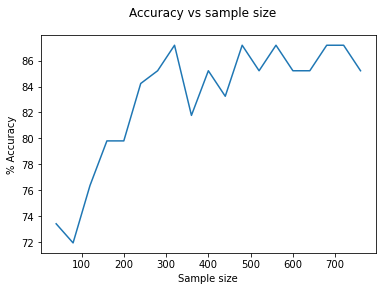

In [8]:
# Loop through to select the number of instances 'x' in increments of 40
# For each 'x',
    # Randomly select 'x' instances
    # Create the ID3 decision tree using those instances
    # Calculate the accuracy of the ID3 tree created on the Test data
x = 40
accuracy = []
smalltree = []
ticker = []
while x < 800:
    smalltree = random.sample(training,x)
    my_tree = build_tree(smalltree)
    accuracy.append(print_accuracy(testing))
    ticker.append(x)
    x+=40
# Plot the learning curve using the accuracy values
    # X-axis will be the number of training instances used for creating the tree
    # Y-axis will be the accuracy in % on the Test data
plt.plot(ticker,accuracy)
plt.ylabel('% Accuracy')
plt.xlabel('Sample size')
plt.suptitle("Accuracy vs sample size")
plt.show()

#Submission Instructions



1.   Complete all tasks above.
2.   Export this notebook as .ipynb
      (File > Download as ipynb)
3.   Upload the .ipynb file on Blackboard



##Rubric

*   (20 points) Gradient Descent Algorithm
*   (2 points) Extra Credit - GD Accuracy Plots
*   (30 points) ID3 Algorithm
*   (3 points) Extra Credit - ID3 Learning Curve



